## Data Loading and Initial Inspection

In [1]:
import pandas as pd

# Write your code below
df=pd.read_csv('athlete_events.csv')
print(df.info)
print(df.isnull().sum())

<bound method DataFrame.info of             ID                      Name Sex   Age  Height  Weight  \
0            1                 A Dijiang   M  24.0   180.0    80.0   
1            2                  A Lamusi   M  23.0   170.0    60.0   
2            3       Gunnar Nielsen Aaby   M  24.0     NaN     NaN   
3            4      Edgar Lindenau Aabye   M  34.0     NaN     NaN   
4            5  Christine Jacoba Aaftink   F  21.0   185.0    82.0   
...        ...                       ...  ..   ...     ...     ...   
271111  135569                Andrzej ya   M  29.0   179.0    89.0   
271112  135570                  Piotr ya   M  27.0   176.0    59.0   
271113  135570                  Piotr ya   M  27.0   176.0    59.0   
271114  135571        Tomasz Ireneusz ya   M  30.0   185.0    96.0   
271115  135571        Tomasz Ireneusz ya   M  34.0   185.0    96.0   

                  Team  NOC        Games  Year  Season            City  \
0                China  CHN  1992 Summer  1992  Summe

## Handling Missing Values in Athlete Data

In [1]:
# Write your code below
#df.dropna(subset=['Age','Height','Weight'], inplace=True)
df = df.dropna(subset=['Age','Height','Weight'])
#df['Medal'].fillna('None', inplace=True)
df['Medal'] = df['Medal'].fillna('None')
print(df.info)
print(df.isnull().sum())


<bound method DataFrame.info of             ID                      Name Sex   Age  Height  Weight  \
0            1                 A Dijiang   M  24.0   180.0    80.0   
1            2                  A Lamusi   M  23.0   170.0    60.0   
4            5  Christine Jacoba Aaftink   F  21.0   185.0    82.0   
5            5  Christine Jacoba Aaftink   F  21.0   185.0    82.0   
6            5  Christine Jacoba Aaftink   F  25.0   185.0    82.0   
...        ...                       ...  ..   ...     ...     ...   
271111  135569                Andrzej ya   M  29.0   179.0    89.0   
271112  135570                  Piotr ya   M  27.0   176.0    59.0   
271113  135570                  Piotr ya   M  27.0   176.0    59.0   
271114  135571        Tomasz Ireneusz ya   M  30.0   185.0    96.0   
271115  135571        Tomasz Ireneusz ya   M  34.0   185.0    96.0   

               Team  NOC        Games  Year  Season            City  \
0             China  CHN  1992 Summer  1992  Summer     

## Analyzing the Growth of Female Participation

<class 'pandas.core.frame.DataFrame'>
Index: 166706 entries, 0 to 271110
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      166706 non-null  int64  
 1   Name    166706 non-null  object 
 2   Sex     166706 non-null  object 
 3   Age     166706 non-null  float64
 4   Height  166706 non-null  float64
 5   Weight  166706 non-null  float64
 6   Team    166706 non-null  object 
 7   NOC     166706 non-null  object 
 8   Games   166706 non-null  object 
 9   Year    166706 non-null  int64  
 10  Season  166706 non-null  object 
 11  City    166706 non-null  object 
 12  Sport   166706 non-null  object 
 13  Event   166706 non-null  object 
 14  Medal   166706 non-null  object 
dtypes: float64(3), int64(2), object(10)
memory usage: 20.3+ MB
    Year Sex    ID
0   1896   M    11
1   1900   M    34
2   1904   M    52
3   1906   M    77
4   1908   M   187
5   1912   M   302
6   1920   F     1
7   1920   M   274
8   1924   F 

<Figure size 2000x1200 with 1 Axes>

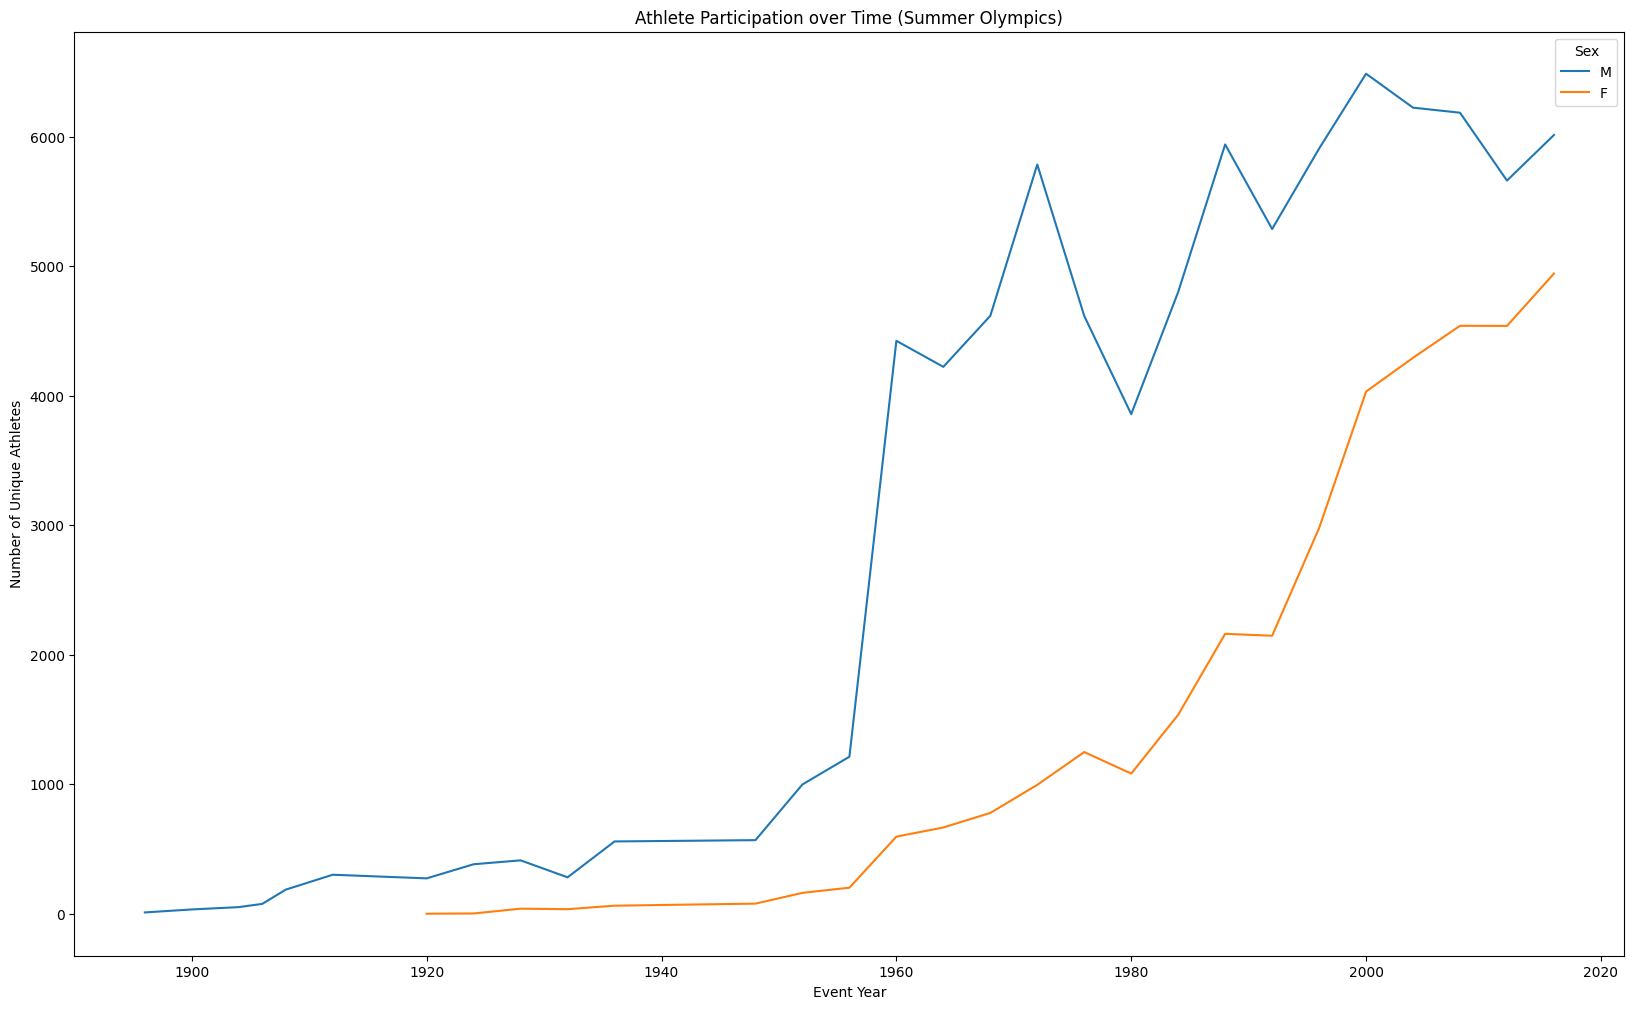

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

# Write your code below
df.info

# 1) Filter for Summer Olympics
summer_df = df[(df['Season']=='Summer')]
summer_df.info()

# 2) Group by Year and Sex, counting unique athletes
gender_counts = summer_df.groupby(['Year','Sex'])['ID'].nunique().reset_index()

# 3) Inspect that there are no nulls in Age/Height/Weight if that test is still failing:
print(gender_counts)
summer_df.info()

# 4) Plot the time series
plt.figure(figsize=(20,12))
sns.lineplot(data=gender_counts,x='Year',y='ID',hue='Sex')
plt.title("Athlete Participation over Time (Summer Olympics)")
plt.ylabel("Number of Unique Athletes")
plt.xlabel("Event Year")
plt.show()


## Distributions of Physical Attributes

<class 'pandas.core.frame.DataFrame'>
Index: 206165 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      206165 non-null  int64  
 1   Name    206165 non-null  object 
 2   Sex     206165 non-null  object 
 3   Age     206165 non-null  float64
 4   Height  206165 non-null  float64
 5   Weight  206165 non-null  float64
 6   Team    206165 non-null  object 
 7   NOC     206165 non-null  object 
 8   Games   206165 non-null  object 
 9   Year    206165 non-null  int64  
 10  Season  206165 non-null  object 
 11  City    206165 non-null  object 
 12  Sport   206165 non-null  object 
 13  Event   206165 non-null  object 
 14  Medal   206165 non-null  object 
dtypes: float64(3), int64(2), object(10)
memory usage: 25.2+ MB
            ID                      Name Sex   Age  Height  Weight  \
0            1                 A Dijiang   M  24.0   180.0    80.0   
1            2                  A Lamusi   M

<Figure size 640x480 with 1 Axes>

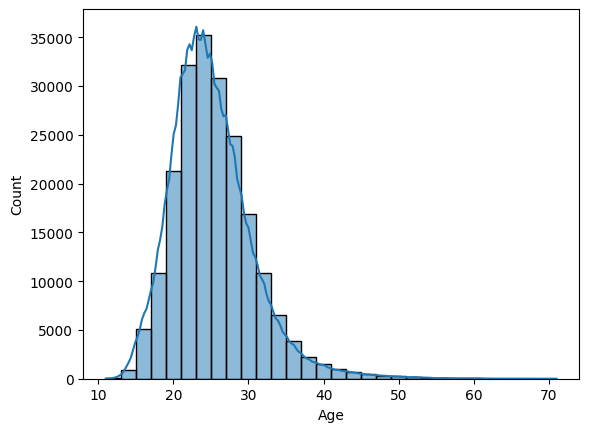

<Figure size 640x480 with 1 Axes>

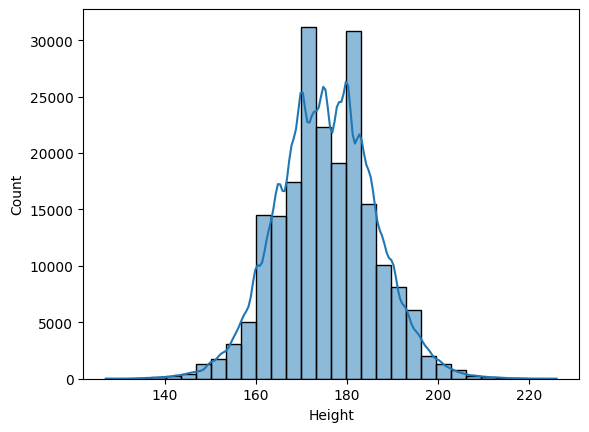

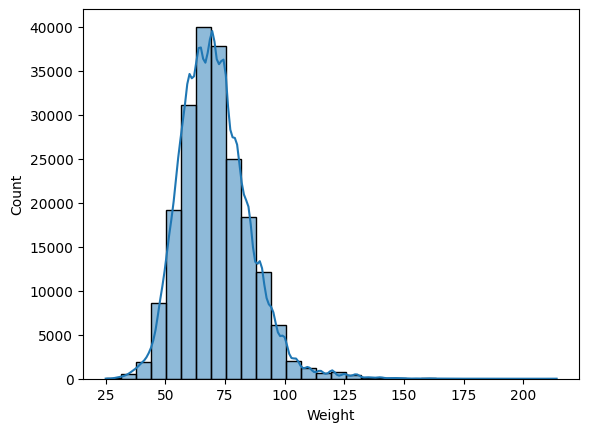

<Figure size 640x480 with 1 Axes>

In [1]:
# Write your code below
import seaborn as sns
import matplotlib.pyplot as plt

# Step 0: Check database structure
df.info()
print(df)

# Step 1: Histogram comprising "Age" Data
sns.histplot(data=df['Age'],bins=30,kde=True)
plt.show()

# Step 2: Histogram comprising "Height" Data
sns.histplot(data=df['Height'],bins=30,kde=True)
plt.show()

# Step 2: Histogram comprising "Weight" Data
sns.histplot(data=df['Weight'],bins=30,kde=True)
plt.show()

## Comparing Physical Traits Across Sports

<class 'pandas.core.frame.DataFrame'>
Index: 206165 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      206165 non-null  int64  
 1   Name    206165 non-null  object 
 2   Sex     206165 non-null  object 
 3   Age     206165 non-null  float64
 4   Height  206165 non-null  float64
 5   Weight  206165 non-null  float64
 6   Team    206165 non-null  object 
 7   NOC     206165 non-null  object 
 8   Games   206165 non-null  object 
 9   Year    206165 non-null  int64  
 10  Season  206165 non-null  object 
 11  City    206165 non-null  object 
 12  Sport   206165 non-null  object 
 13  Event   206165 non-null  object 
 14  Medal   206165 non-null  object 
dtypes: float64(3), int64(2), object(10)
memory usage: 25.2+ MB
            ID                      Name Sex   Age  Height  Weight  \
0            1                 A Dijiang   M  24.0   180.0    80.0   
1            2                  A Lamusi   M

<Figure size 640x480 with 1 Axes>

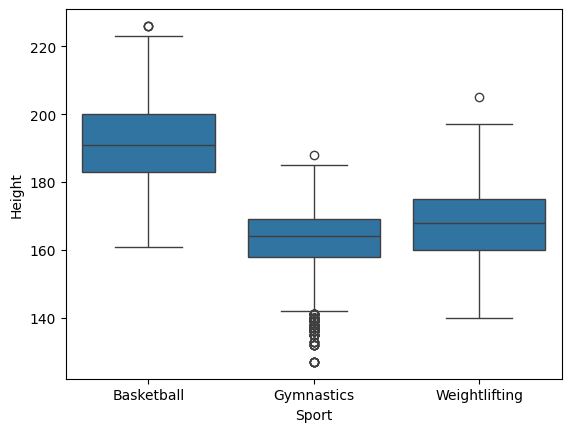

<Figure size 640x480 with 1 Axes>

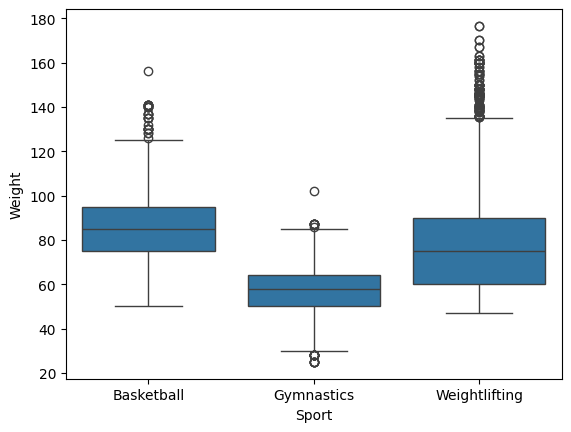

In [1]:
# Write your code below
import seaborn as sns
import matplotlib.pyplot as plt

# Step 0: Check database structure
df.info()
print(df)

# Step 1: Filter Sport Column with rows consisting Basketball, Gym, and Weightlifting
target_sports=['Basketball','Gymnastics','Weightlifting']
sports_df = df[df['Sport'].isin(target_sports)]
sports_df.info()

# Step 2: Boxplot comprising "Sports" on x-axis and 'Height' on y axis
sns.boxplot(data=sports_df,x='Sport',y='Height')
plt.show()

# Step 3: Another boxplot comprising "Sports" on x-axis and 'Weight' on y axis
sns.boxplot(data=sports_df,x='Sport',y='Weight')
plt.show()

## Tracing Athlete Evolution Over Time

<class 'pandas.core.frame.DataFrame'>
Index: 206165 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      206165 non-null  int64  
 1   Name    206165 non-null  object 
 2   Sex     206165 non-null  object 
 3   Age     206165 non-null  float64
 4   Height  206165 non-null  float64
 5   Weight  206165 non-null  float64
 6   Team    206165 non-null  object 
 7   NOC     206165 non-null  object 
 8   Games   206165 non-null  object 
 9   Year    206165 non-null  int64  
 10  Season  206165 non-null  object 
 11  City    206165 non-null  object 
 12  Sport   206165 non-null  object 
 13  Event   206165 non-null  object 
 14  Medal   206165 non-null  object 
dtypes: float64(3), int64(2), object(10)
memory usage: 25.2+ MB
            ID                      Name Sex   Age  Height  Weight  \
0            1                 A Dijiang   M  24.0   180.0    80.0   
1            2                  A Lamusi   M

<Figure size 2000x1200 with 1 Axes>

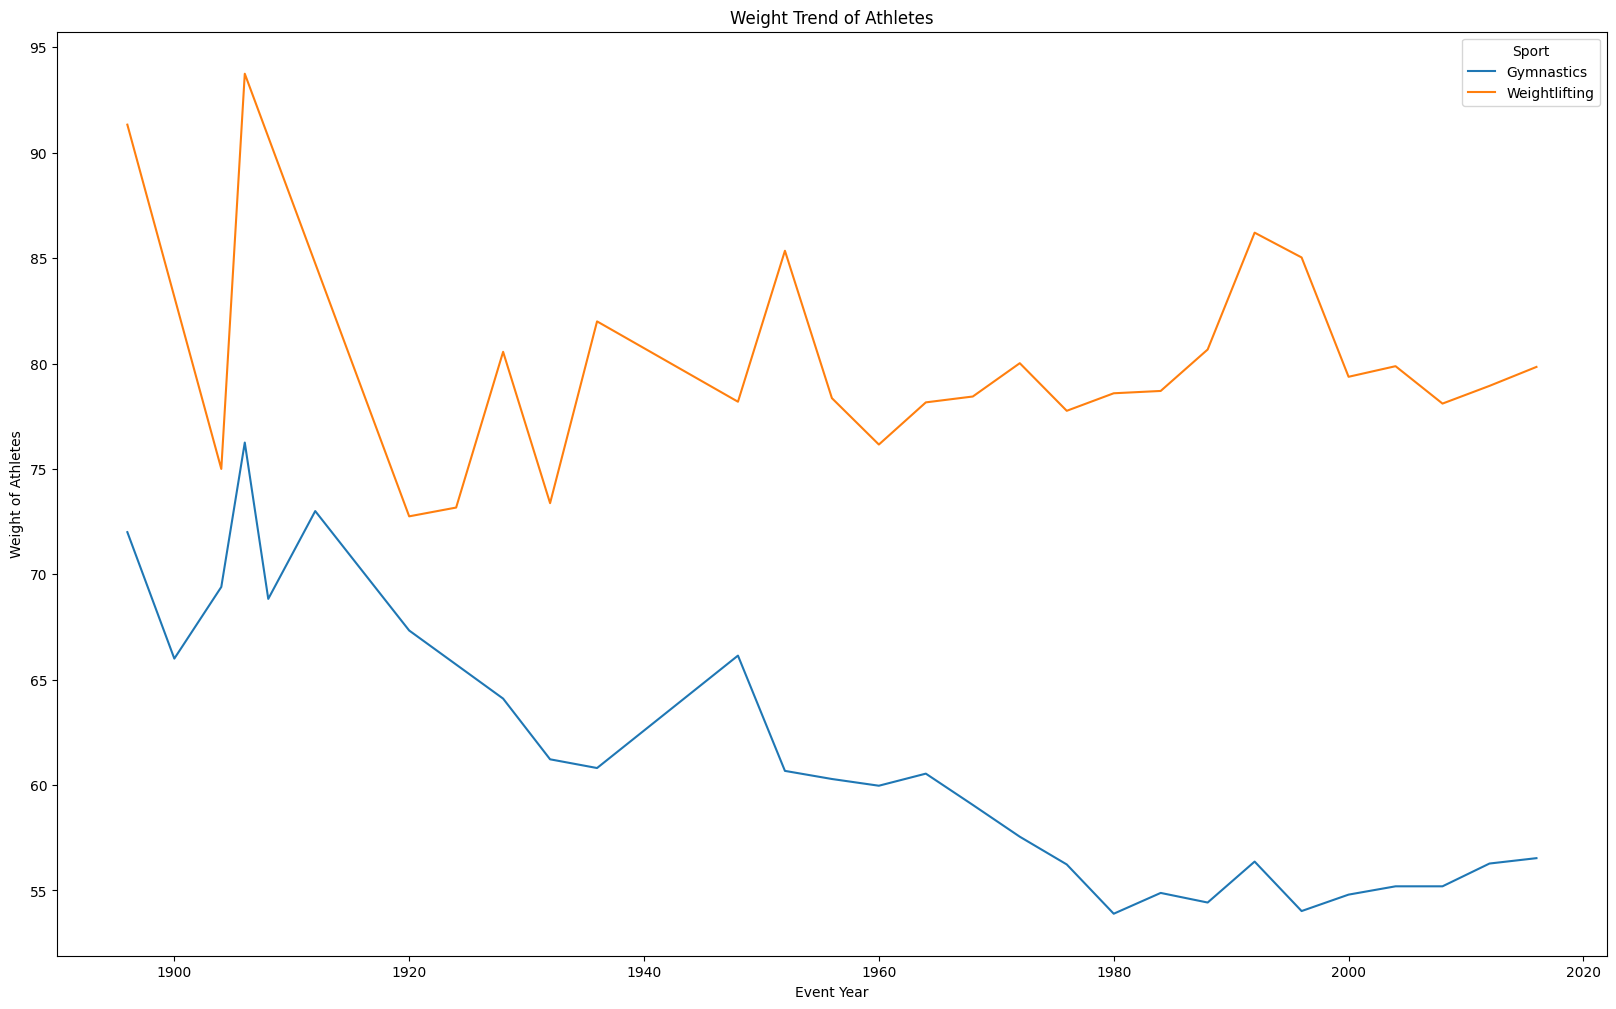

In [1]:
# Write your code below
import seaborn as sns
import matplotlib.pyplot as plt

# Step 0: Check database structure
df.info()
print(df)

# Step 1: Filter Sport Column with rows consisting Gym, and Weightlifting
target_sports=['Gymnastics','Weightlifting']
evo_df = df[df['Sport'].isin(target_sports)]
evo_df.info()

# Step 2: weight_trends with mean computation of 'weight' group by 'Year' and 'Sport'
weight_trends = evo_df.groupby(['Year','Sport'])['Weight'].mean().reset_index()

# Step 3: Another lineplot comprising "Year" on x-axis and 'Weight' on y axis, overlay by 'Sports'
plt.figure(figsize = (20,12))
sns.lineplot(data=weight_trends,x='Year',y='Weight',hue='Sport')
plt.title("Weight Trend of Athletes")
plt.ylabel("Weight of Athletes")
plt.xlabel("Event Year")
plt.show()

## Evaluating Medal Success by Country

<class 'pandas.core.frame.DataFrame'>
Index: 206165 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      206165 non-null  int64  
 1   Name    206165 non-null  object 
 2   Sex     206165 non-null  object 
 3   Age     206165 non-null  float64
 4   Height  206165 non-null  float64
 5   Weight  206165 non-null  float64
 6   Team    206165 non-null  object 
 7   NOC     206165 non-null  object 
 8   Games   206165 non-null  object 
 9   Year    206165 non-null  int64  
 10  Season  206165 non-null  object 
 11  City    206165 non-null  object 
 12  Sport   206165 non-null  object 
 13  Event   206165 non-null  object 
 14  Medal   206165 non-null  object 
dtypes: float64(3), int64(2), object(10)
memory usage: 25.2+ MB
            ID                      Name Sex   Age  Height  Weight  \
0            1                 A Dijiang   M  24.0   180.0    80.0   
1            2                  A Lamusi   M

/tmp/ipykernel_51/2228969428.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values,y=top_countries.index,orient="h",palette = "viridis")


<Figure size 2000x1200 with 1 Axes>

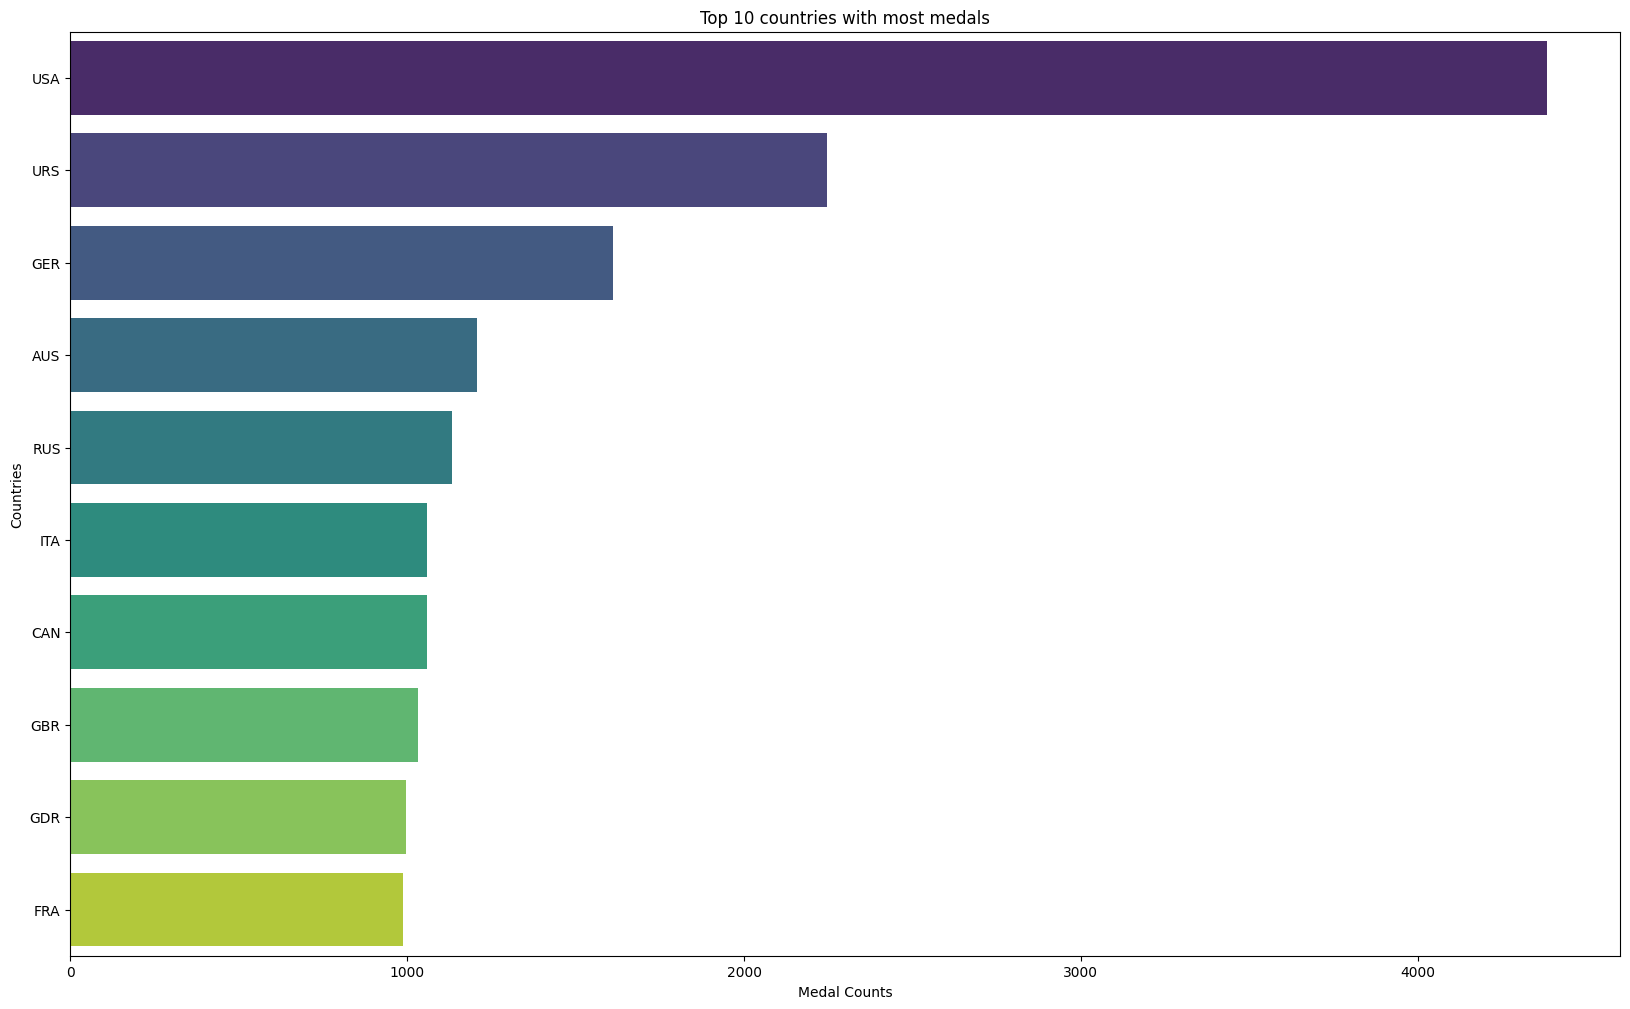

In [1]:
# Write your code below
import seaborn as sns
import matplotlib.pyplot as plt

# Step 0: Check database structure
df.info()
print(df)

# Step 1: Filter Medal Column with rows not equal to "None"
medalists = df[df['Medal'] != 'None']
medalists.info()

# Step 2: Find top countries with most medal counts
#wrong ->top_countries = medalists.groupby('NOC')['Medal'].nunique().reset_index().sort_values(by='Medal',ascending=False).head(10)
top_countries = medalists.groupby('NOC')['Medal'].count().sort_values(ascending=False).head(10)
print(top_countries)

# Step 3: Barplot consisting top10 countries with most medals.
plt.figure(figsize = (20,12))
sns.barplot(x=top_countries.values,y=top_countries.index,orient="h",palette = "viridis")
plt.title("Top 10 countries with most medals")
plt.ylabel("Countries")
plt.xlabel("Medal Counts")
plt.show()